# Week 2 Task 3 — Cognitive load and the data-ink ratio

This notebook follows the Week 2 assignment brief and keeps each task in a separate file.

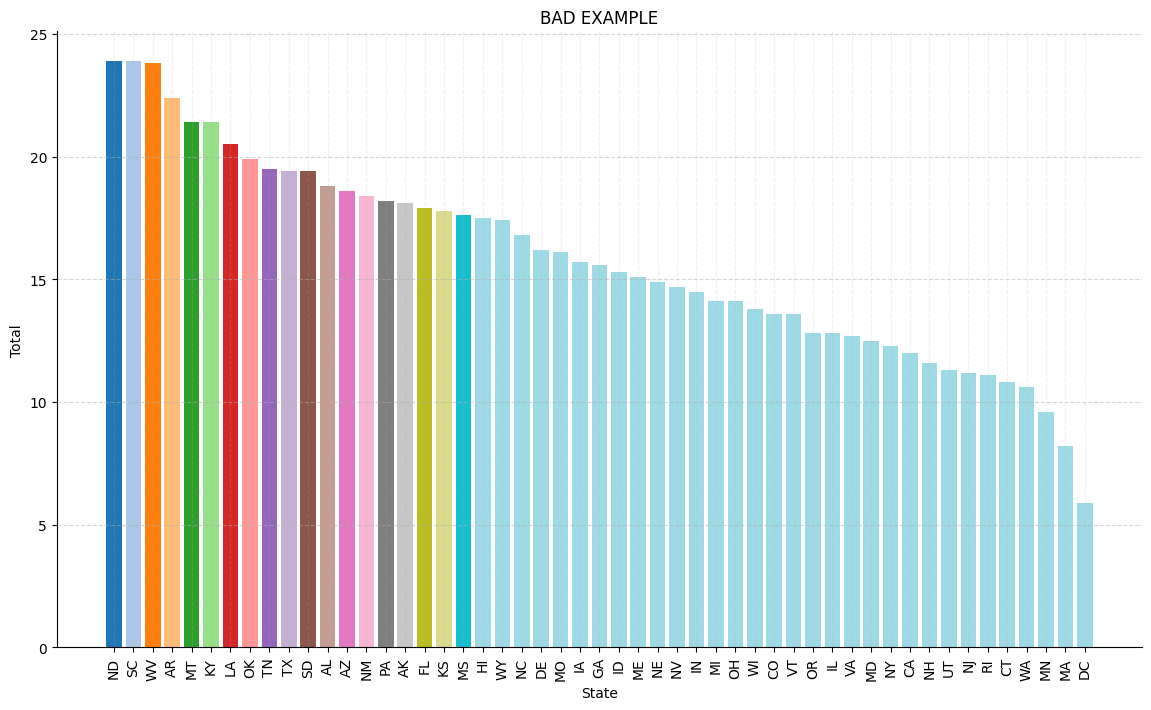

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week2/assignments/data/car_crashes.csv')
if not path.exists():
    path = Path('assignments/data/car_crashes.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week2/assignments/data/car_crashes.csv')

crashes = pd.read_csv(path)
crashes = crashes.sort_values('total', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(14, 8))
ax.bar(crashes['abbrev'], crashes['total'], color=list(plt.cm.tab20(np.arange(len(crashes)))))
ax.set_title('BAD EXAMPLE')
ax.set_xlabel('State')
ax.set_ylabel('Total')
ax.tick_params(axis='x', rotation=90)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.grid(True, axis='x', linestyle='--', alpha=0.2)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.show()


In [ ]:
# A rough data-ink audit: most of the marks in the overloaded version are extraneous decoration or labels; only the bar heights encode the data. The goal is not to remove all ink, but to remove the ink that does not carry information.
# Things to classify: bars, gridlines, labels, legend, frame, colour encoding, title, tick marks.


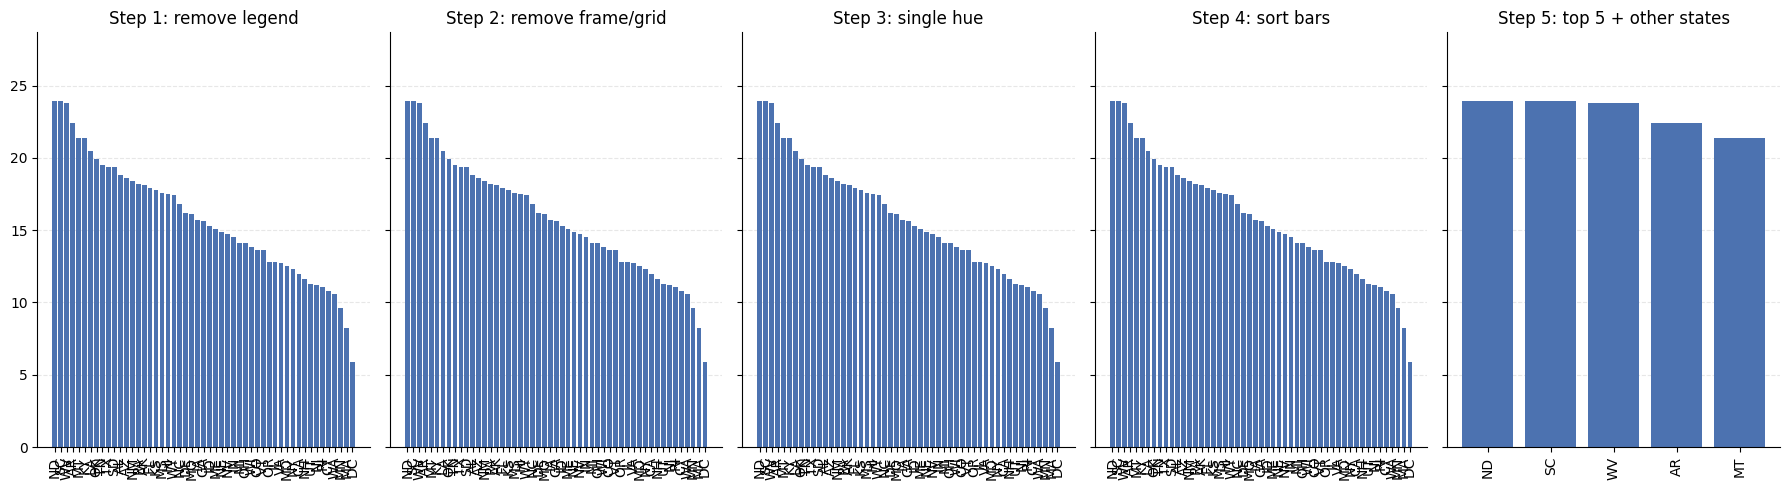

In [2]:
# Five-panel progression from clutter to cleaner chart, each panel labelled as the step taken.
fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=True)
for ax in axes:
    ax.set_ylim(0, crashes['total'].max() * 1.2)
    ax.set_axisbelow(True)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

axes[0].bar(crashes['abbrev'], crashes['total'], color='#4c72b0')
axes[0].set_title('Step 1: remove legend')

axes[1].bar(crashes['abbrev'], crashes['total'], color='#4c72b0')
axes[1].set_title('Step 2: remove frame/grid')

axes[2].bar(crashes['abbrev'], crashes['total'], color='#4c72b0')
axes[2].set_title('Step 3: single hue')

axes[3].bar(crashes['abbrev'], crashes['total'], color='#4c72b0')
axes[3].set_title('Step 4: sort bars')

axes[4].bar(crashes['abbrev'].head(5), crashes['total'].head(5), color='#4c72b0')
axes[4].set_title('Step 5: top 5 + other states')

for ax in axes:
    ax.tick_params(axis='x', rotation=90)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [ ]:
# Chunking the 51 states into a small number of groups reduces working memory load, but it hides detail. That is the trade-off: the chart becomes easier to read by collapsing the long tail and showing a summary.


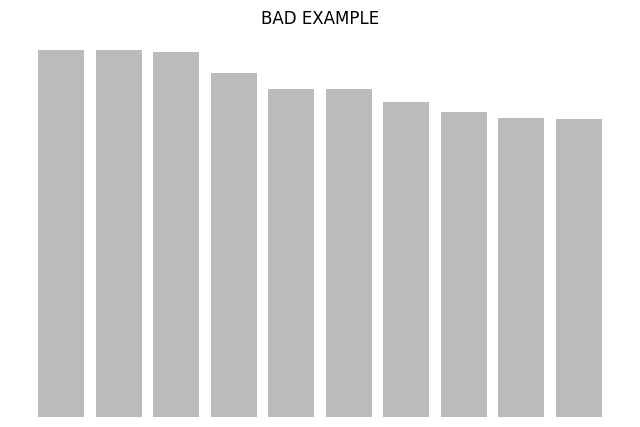

In [3]:
# Over-strip version: if you remove the axis scale, the plot loses all meaning. Data-ink ratio is a heuristic, not a rule.
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(crashes['abbrev'].head(10), crashes['total'].head(10), color='#bbbbbb')
ax.set_title('BAD EXAMPLE')
ax.axis('off')
plt.show()


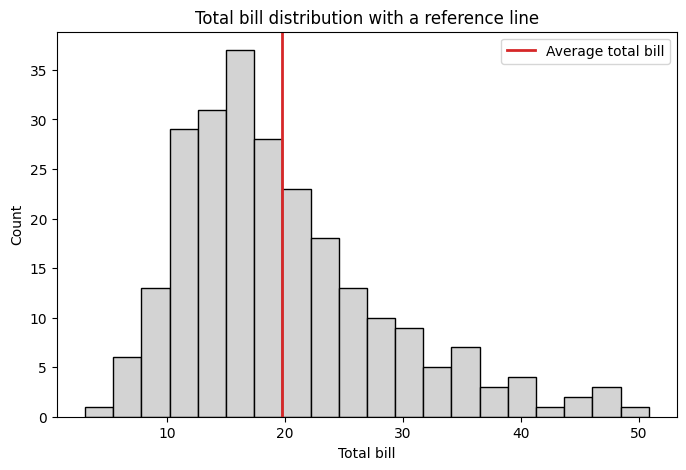

In [5]:
# A direct label or reference line can reduce cognitive load because the reader does not need to calculate the value from the scale. This is why the slogan 'maximize data-ink' is only a heuristic: sometimes a little extra ink makes the message easier to decode.
# Example from tips.csv: a reference line for the average bill can make the comparison immediate.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week2/assignments/data/tips.csv')
if not path.exists():
    path = Path('assignments/data/tips.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week2/assignments/data/tips.csv')

tips = pd.read_csv(path)
avg_total = tips['total_bill'].mean()
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(tips['total_bill'], bins=20, color='lightgray', edgecolor='black')
ax.axvline(avg_total, color='#d62728', linewidth=2, label='Average total bill')
ax.set_title('Total bill distribution with a reference line')
ax.set_xlabel('Total bill')
ax.set_ylabel('Count')
ax.legend()
plt.show()